# Model Comparison and Evaluation

## Introduction and Objectives

The purpose of this notebook is to compare regression models using the dataset obtained from the data preparation and baseline notebook. The overall aim of this project is to investigate whether the processing time of building control applications can be predicted using characteristics known at the time of submission. 

The models being compared are :
- Linear Regression
- Decision Tree Regression
- K-Nearest Neighbours (KNN) Regression
  
The objective of this notebook is to evaluate and compare the predictive performance of these models against the baseline model developed in Milestone 2, using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). This will help determine which regression model is most effective at predicting application processing times

## Data Preparation

In [1]:
import pandas as pd

df_model = pd.read_csv("Downloads/CT4101 Portfolio/Data/cleaned_applications.csv", low_memory=False)

In [2]:
print(df_model.shape)

(42711, 65)


In [3]:
df_model["submission_date"] = pd.to_datetime(df_model["submission_date"])

In [4]:
df_model.head()

,application_reference_no,application_type,local_authority,submission_no,submission_date,date_permission_was_granted,planning_permission_reference_no,seven_days_submission_no,classification_of_works_or_building,development_description,...,appeal_type,decision_type,applicant_name,applicant_address_line_1,applicant_address_line_2,applicant_town,applicant_county,applicant_postcode,is_the_applicant_the_owner_or_leaseholder,processing_time_days
0,FSC2000402LH,fire_safety_certificate_application_fsc,Louth County Council,3000032,2020-07-13,2020-08-03,20321,NaN,^extension_to_a_building^,Permission for an extension that will consist ...,...,NaN,granted,Leoni Carroll,Sacred Heart School\nSunnyside,NaN,Drogheda,louth,A92 K796,owner,184.0
1,DAC2000031FL,disability_access_certificate_application_dac,Fingal County Council,4000018,2020-07-13,NaN,F20A/0294,NaN,^construction_new_building^,The proposed development will consist of the r...,...,NaN,granted_with_conditions,Brian O'Rourke,9 Prussia Street\nDUblin 7,NaN,Dublin,dublin_7,NaN,owner,73.0
2,DAC2000553LH,disability_access_certificate_application_dac,Louth County Council,4000019,2020-07-13,2020-08-03,20321,NaN,^extension_to_a_building^,Permission for an extension that will consist ...,...,NaN,granted,Leoni Carroll,Sacred Heart School\nSunnyside,NaN,Drogheda,louth,A92 K796,owner,380.0
3,FSC2000348FL,fire_safety_certificate_application_fsc,Fingal County Council,3000031,2020-07-13,NaN,F20A/0294,NaN,^construction_new_building^,The proposed development will consist of the r...,...,NaN,granted_with_conditions,Brian O'Rourke,9 Prussia Street\nDUblin 7,NaN,Dublin,dublin_7,NaN,owner,73.0
4,FSC2000101CW/7DN,fire_safety_certificate_application_fsc,Carlow County Council,3000033,2020-07-14,2019-11-26,19342,8447149,^extension_to_a_building^,to construct an extension to the rear of exist...,...,NaN,granted,Michelle Doorley,Ballinkillen N.S.\nBallinkillen,NaN,Muinebeag,carlow,R21 Y803,owner,59.0


In [5]:
print(df_model.columns.tolist())

['application_reference_no', 'application_type', 'local_authority', 'submission_no', 'submission_date', 'date_permission_was_granted', 'planning_permission_reference_no', 'seven_days_submission_no', 'classification_of_works_or_building', 'development_description', 'description_of_changes_from_original_application', 'location_of_the_proposed_development', 'eircode', 'street', 'address_line_2', 'town', 'county', 'LAT', 'LONGITUDE', 'related_fsc_application', 'use_of_proposed_works_or_building', 'sub_group', 'existing_use_of_building', 'main_construction_type', 'site_area', 'no_of_basement_stories', 'no_of_basement_stories_original', 'no_of_stories_above_ground_level', 'no_of_stories_above_ground_level_original', 'height_of_top_floor_above_ground_level', 'height_top_floor_above_ground_level_original', 'floor_area_of_building', 'floor_area_of_building_original', 'total_area_of_ground_floor', 'total_area_of_ground_floor_original', 'total_area_of_material_change_of_use', 'total_area_of_exist

In [6]:
features = [
    "application_type",
    "local_authority",
    "classification_of_works_or_building",
    "sub_group",
    "use_of_proposed_works_or_building",
    "main_construction_type",
    "site_area",
    "floor_area_of_building",
    "total_area_of_ground_floor",
    "no_of_stories_above_ground_level",
    "no_of_basement_stories",
    "height_of_top_floor_above_ground_level"
]

X = df_model[features]
y = df_model["processing_time_days"]

In [7]:
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (42711, 12)
Target shape: (42711,)


In [8]:
from sklearn.model_selection import train_test_split

df_model["submission_date"] = pd.to_datetime(df_model["submission_date"])

df_model = df_model.sort_values("submission_date").reset_index(drop=True)

X = df_model[features]
y = df_model["processing_time_days"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 34168
Testing observations: 8543


### Preprocessing

The same preprocessing pipeline from Notebook 2 was used to ensure a consistent comparison between regression models. Missing numerical values are imputed using the median, while missing categorical values are imputed using the most frequent category. One-hot encoding is applied to categorical predictors to make them suitable for regression models.

Preprocessing is incorporated into the model pipelines to ensure that transformations are fitted using the training data only, reducing the risk of data leakage.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_features = X.select_dtypes(include=["object", "category"]).columns
numerical_features = X.select_dtypes(include=["number"]).columns

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

## Model Training

### Linear Regression

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

model = make_pipeline(preprocessor, LinearRegression())
model.fit(X_train, y_train)
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = root_mean_squared_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 50.12393910593853
RMSE: 59.24301378418615
R²: -0.3152481174641417


- The MAE is 50.124 which is the average absolute difference between predicted and actual processing times, in days.
- The RMSE is 59.243 which is a measurement of prediction error in days. RMSE penalises larger prediction errors more heavily than MAE.
- The $R^2$ value of -0.315 measures how well the model explains variation in processing times.A negative $R^2$ means its squared prediction errors are worse than predicting the test-set mean.


##### Comparision with baseline:
The linear regression model performs worse than the baseline model used in the Data Preparation and Baseline notebook which achieved an MAE of 32.861 days and an RMSE of 52.781 days. This leads to the belief that a linear regression model is currently not an effective model for predicting processing times in this dataset.

### Decision Tree Regression

In [11]:
from sklearn.tree import DecisionTreeRegressor

tree = make_pipeline(
    preprocessor,
    DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=10,
        random_state=42
    )
)

tree.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['site_area', 'floor_area_of_building', 'total_area_of_ground_floor',
       'no_of_stories_above_ground_level', 'no_of_basement_stories',
       'height_of_top_floor_above_ground_level'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(ste...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['application_type', 'local_authority',
       'classification_of_works_or_building', 'sub_group',
       'use_of_proposed_works_or_building', 'main_construction_type'],
      dtype='object'))])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(max_depth=4, min_samples_leaf=10,
                                       random_state=42))])

The max depth of 4 limits the depth of the tree to control complexity. 
The min samples leaf of 10 requires ar least 10 training observations in each leaf. 
The random state of 42 makes the estimator's random choices reproducible. 

Increasing the maximum depth of the Decision Tree from 4 to 5 slightly reduced the MAE from 45.941 to 45.720 days. This was done in an exploratory test., and was not used for formal hyperparamter selection. However, RMSE increased from 63.530 to 64.163 days, indicating that the deeper tree did not consistently improve predictive performance.

These preliminary results suggest that increasing tree complexity does not necessarily improve predictions. Further comparison using a validation set drawn from the training data is required to select an appropriate maximum depth.

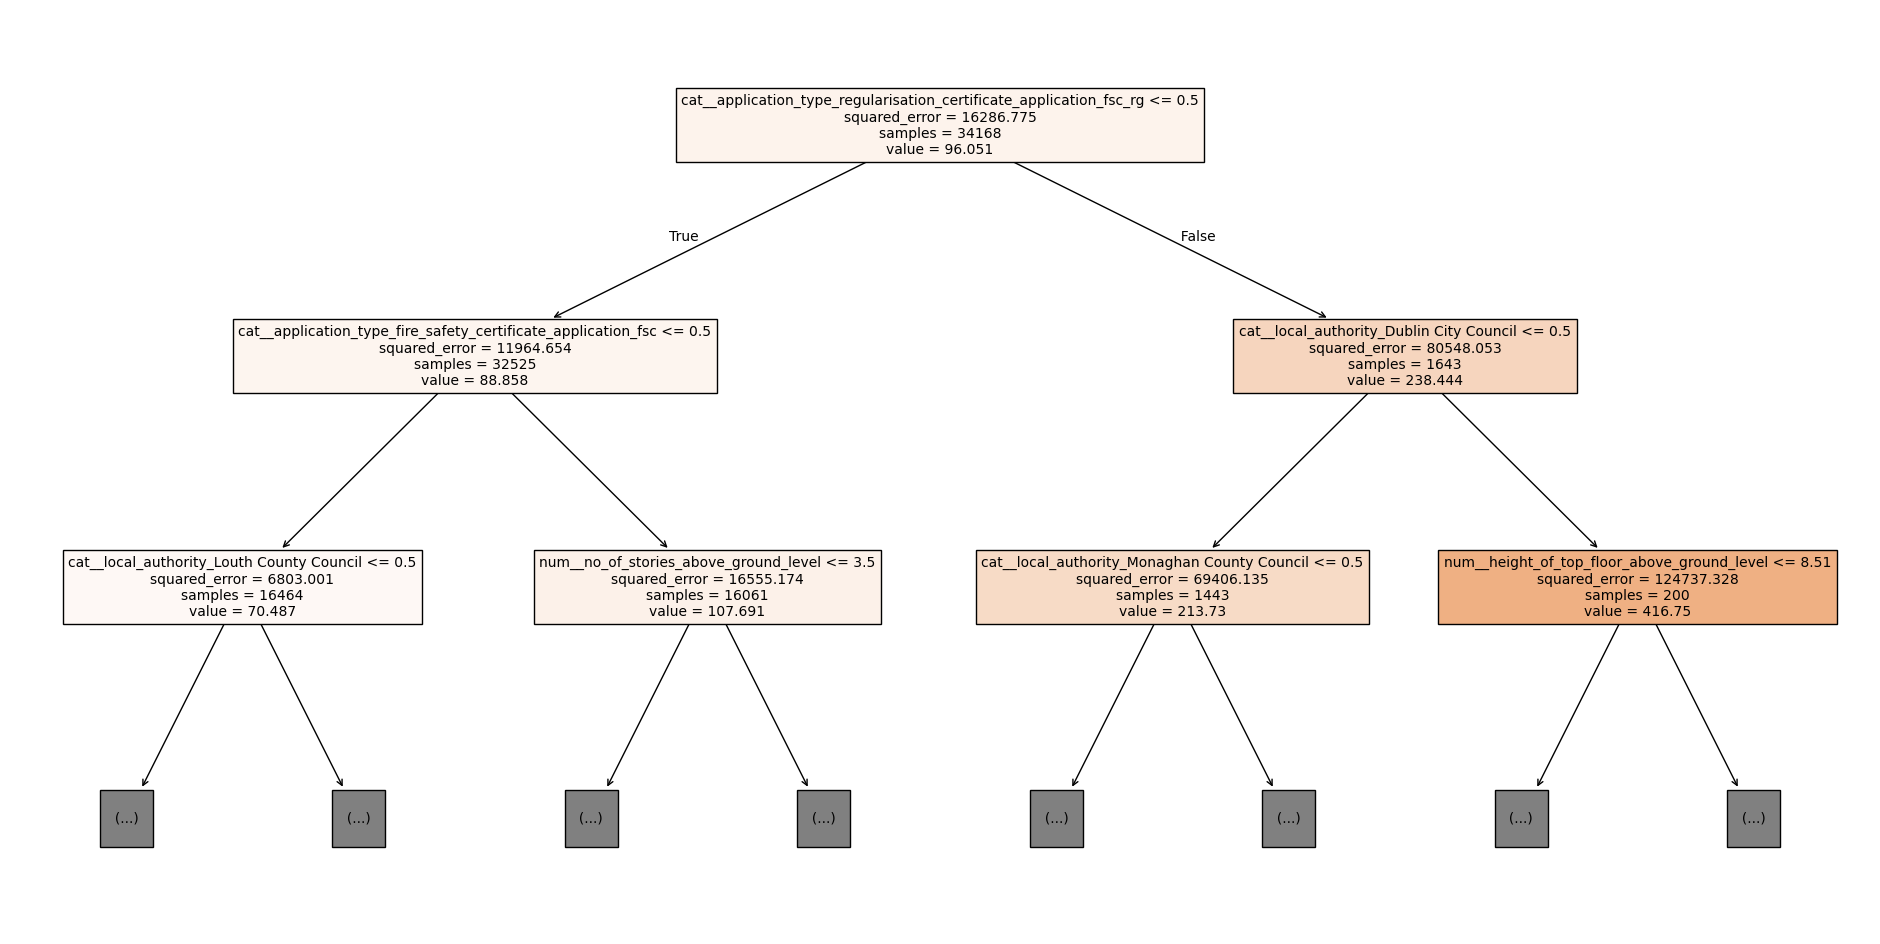

In [30]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

fitted_tree = tree.named_steps["decisiontreeregressor"]

feature_names = tree.named_steps["columntransformer"].get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    fitted_tree,
    feature_names=feature_names,
    filled=True,
    max_depth=2,
    fontsize=10
)

plt.show()

The decision tree illustrates how the model uses different building characteristics to predict application processing times.

The first split is based on whether an application is a Regularisation Certificate Application (FSC RG). The training observations in this category have a mean processing time of approximately 238.44 days, compared with 88.86 days for the remaining applications.

Further splits involve application type, local authority, number of storeys above ground level and height of the top floor. This suggests that both categorical and numerical predictors contribute to the model's predictions.

The visualisation displays only the first two levels of the decision tree to improve readability. The complete model has a maximum depth of four.

In [31]:
tree_pred = tree.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = root_mean_squared_error(y_test, tree_pred)
tree_r2 = r2_score(y_test, tree_pred)

print("MAE:", tree_mae)
print("RMSE:", tree_rmse)
print("R²:", tree_r2)

MAE: 45.94079999736384
RMSE: 63.530306986557896
R²: -0.5124997424680258


- The MAE is 45.941 which is the average absolute difference between predicted and actual processing times, in days.
- The RMSE is 63.530 which is a measurement of prediction error in days. RMSE penalises larger prediction errors more heavily than MAE.
- The $R^2$ value of -0.512 measures how well the model explains variation in processing times. A negative $R^2$ means its squared prediction errors are worse than predicting the test-set mean.

##### Comparsion with baseline:
The Decision Tree Regression model performs worse than the baseline model, which achieved an MAE of 32.861 days and an RMSE of 52.781 days.

Compared with Linear Regression, Decision Tree Regression achieves a lower MAE (45.941 versus 50.124 days), but a higher RMSE (63.530 versus 59.243 days). This suggests that while the Decision Tree produces smaller absolute errors on average, it may be making some larger prediction errors.

Overall, neither regression model has performed better than the baseline on the current test dataset.

### KNN Regression

KNN Regression is a supervised learning method that predicts a continuous numerical value using the target values of the nearest observations in the training dataset.

For this project, KNN Regression is used to predict application processing times based on similar building control applications. The model uses distances between observations to identify the nearest neighbours and calculate a predicted processing time.

In [14]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

knn = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    KNeighborsRegressor(n_neighbors=7, weights="distance")
)

knn.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['site_area', 'floor_area_of_building', 'total_area_of_ground_floor',
       'no_of_stories_above_ground_level', 'no_of_basement_stories',
       'height_of_top_floor_above_ground_level'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(ste...
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['application_type', 'local_authority',
       'classification_of_works_or_building', 'sub_group',
       'use_of_proposed_works_or_building', 'main_construction_type'],
      dtype='object'))])),
                ('standardscaler', StandardScaler(with_mean=False)),
                ('kneighborsregressor',
                 KNeighborsRegressor(n_neighbors=7, weights='distance'))])

In [15]:
split = int(len(X_train) * 0.8)

X_fit = X_train.iloc[:split]
X_val = X_train.iloc[split:]

y_fit = y_train.iloc[:split]
y_val = y_train.iloc[split:]

In [16]:
knn.fit(X_fit, y_fit)

knn_val_pred = knn.predict(X_val)

knn_val_mae = mean_absolute_error(y_val, knn_val_pred)

print("Validation MAE:", knn_val_mae)

Validation MAE: 68.8620665960032


In [17]:
for k in [5, 7, 15]:
    knn = make_pipeline(
        preprocessor,
        StandardScaler(with_mean=False),
        KNeighborsRegressor(n_neighbors=k, weights="distance")
    )

    knn.fit(X_fit, y_fit)
    val_pred = knn.predict(X_val)

    val_mae = mean_absolute_error(y_val, val_pred)

    print(f"k={k}, Validation MAE={val_mae:.3f} days")

k=5, Validation MAE=70.808 days
k=7, Validation MAE=68.862 days
k=15, Validation MAE=65.965 days


##### KNN Hyperparameter Selection

Three values of the number of nearest neighbours (k = 5, 7 and 15) were investigated using a chronological validation split taken from the training data.

The validation MAE decreased from 70.808 days for k = 5 to 68.862 days for k = 7 and 65.965 days for k = 15.

Of the values tested, k = 15 achieved the lowest validation MAE and was therefore selected for the final KNN Regression model. Distance weighting was used throughout, giving greater influence to closer observations.

In [18]:
knn_final = make_pipeline(
    preprocessor,
    StandardScaler(with_mean=False),
    KNeighborsRegressor(
        n_neighbors=15,
        weights="distance"
    )
)

knn_final.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['site_area', 'floor_area_of_building', 'total_area_of_ground_floor',
       'no_of_stories_above_ground_level', 'no_of_basement_stories',
       'height_of_top_floor_above_ground_level'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(ste...
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['application_type', 'local_authority',
       'classification_of_works_or_building', 'sub_group',
       'use_of_proposed_works_or_building', 'main_construction_type'],
      dtype='object'))])),
                ('standardscaler', StandardScaler(with_mean=False)),
                ('kneighborsregressor',
                 KNeighborsRegressor(n_neighbors=15, weights='distance'))])

In [19]:
knn_pred = knn_final.predict(X_test)

knn_mae = mean_absolute_error(y_test, knn_pred)
knn_rmse = root_mean_squared_error(y_test, knn_pred)
knn_r2 = r2_score(y_test, knn_pred)

print("MAE:", knn_mae)
print("RMSE:", knn_rmse)
print("R²:", knn_r2)

MAE: 51.44148181255106
RMSE: 76.79952145035502
R²: -1.2102959572167133


- MAE = 51.441 days: On average, KNN predictions differ from actual processing times by approximately 51.44 days.
- RMSE = 76.800 days: The model has substantial prediction errors, with larger errors contributing more heavily to RMSE.
- $R^2$ = −1.210: The negative $R^2$ indicates that KNN performs worse, in terms of squared prediction error, than simply predicting the mean processing time of the test observations.

##### Comparison with the baseline and other regression models:
KNN Regression achieved a higher MAE and RMSE than the baseline, Linear Regression and Decision Tree Regression models.
The model used 15 nearest neighbours with distance weighting, selected after comparing k = 5, 7 and 15 using a chronological validation set.
These results suggest that KNN Regression, with the selected settings, is not performing well on the current test dataset.

In [21]:
comparison = pd.DataFrame({
    "model": [ 
        "Baseline (Median)",
        "Linear Regression", 
        "Decision Tree Regression", 
        "KNN Regression"
    ], 
    "MAE" : [
        32.860704,
        mae, 
        tree_mae, 
        knn_mae
    ], 
    "RMSE" : [
        52.780713,
        rmse, 
        tree_rmse,
        knn_rmse
    ],

})

comparison.round(3)
        

,model,MAE,RMSE
0,Baseline (Median),32.861,52.781
1,Linear Regression,50.124,59.243
2,Decision Tree Regression,45.941,63.530
3,KNN Regression,51.441,76.800


The median baseline achieves the lowest MAE and RMSE, meaning none of the three learned regression models perform better than it on the current test data. Between the learned models, Decision Tree Regression has the lowest MAE, while Linear Regression has the lowest RMSE. KNN Regression has the highest prediction errors according to both RMSE and MAE.

## Visualisation 

In [24]:
print(X.dtypes)

application_type                           object
local_authority                            object
classification_of_works_or_building        object
sub_group                                  object
use_of_proposed_works_or_building          object
main_construction_type                     object
site_area                                 float64
floor_area_of_building                    float64
total_area_of_ground_floor                float64
no_of_stories_above_ground_level          float64
no_of_basement_stories                    float64
height_of_top_floor_above_ground_level    float64
dtype: object


In [22]:
tree_residuals = y_test - tree_pred

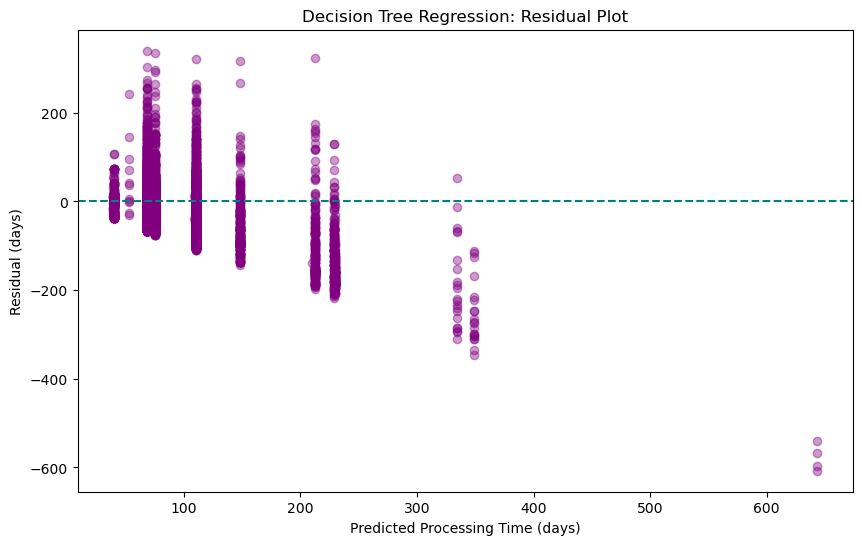

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(tree_pred, tree_residuals, alpha=0.3, color = "purple")

plt.axhline(y=0, color="teal", linestyle="--")

plt.xlabel("Predicted Processing Time (days)")
plt.ylabel("Residual (days)")
plt.title("Decision Tree Regression: Residual Plot")

plt.show()

The plot shows vertical groups because a decision tree assigns the same predicted value to multiple observations in the same leaf. It also shows that substantial negative residuals, which suggested that the model overestimates processing times for certain applications. The positive residuals show that the model also underestimates processing times for certain applications. The large negatuve residuals indicate that the model struggles to predict certain applications accurately.

## Error Analysis

In [28]:
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": tree_pred,
    "Residual": tree_residuals
})

error_analysis["Absolute Error"] = error_analysis["Residual"].abs()

error_analysis.sort_values("Absolute Error", ascending=False).head(10)

,Actual,Predicted,Residual,Absolute Error
36163,36.0,643.463415,-607.463415,607.463415
41243,46.0,643.463415,-597.463415,597.463415
41440,75.0,643.463415,-568.463415,568.463415
34333,103.0,643.463415,-540.463415,540.463415
37734,3.0,349.065574,-346.065574,346.065574
34984,408.0,68.114330,339.885670,339.885670
34186,14.0,349.065574,-335.065574,335.065574
35005,410.0,75.685899,334.314101,334.314101
34479,537.0,212.790453,324.209547,324.209547
34213,432.0,110.281958,321.718042,321.718042


The 10 largest absolute prediction errors were analysed to identify where the Decision Tree Regression models performs poorly. The largest errors include extreme overestimations, the model predicted approximately 643 days for applications that took between 36 and 103 days to process. There were also substantial underestimations. For example, an application with an actual processing time of 408 days had a prediction time of approximately 68 days. These findings suggest that the Decision Tree Regresssion Model struggles to accurately predict some unusually short and long processing times with accuracy. The presence of both positive and negative residuals is consistent with the patterns observed in the residual plot.

## Conclusion

The median baseline model performed best overall, with the lowest MAE and RMSE on the test dataset. Between the three learned models, Decision Tree Regression achieved the lowest MAE of 45.941 days, and Linear Regression achieved the lower RMSE of 59.243 days.

These findings indicate that none of the learned regression models, with their current settings, improved upon the baseline model when predicting processing times for building control applications. 


##### Limitations

- The models only use information available at submission, so they cannot account for events that happen during the application process.
- All 3 learned models performed worse than the baseline on the test dataset.
- The Decision Tree eroor analysis shows some substantial overestimations and underestimations.
- The models were evaluated using a time-based train/test split, so performance may differ across time periods.


##### Next Steps

- Investigate whether other predictor variables or improved feature engineering could improve accuracy.
- Tune the Decision Tree using a training-only validation set.
- Look into why certain applications have particularly large prediction errors.
- Consider other suitable regression models in the final portfolio. 